In [14]:
import pandas as pd
# UCI Machine Learning Repository( Water traetment Plant Data set)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/water-treatment/water-treatment.data"
df = pd.read_csv(url, header=None, na_values='?')

print("Loaded Data Successfully")
print(f"total rows and columns: {df.shape}")
df.head()



Loaded Data Successfully
total rows and columns: (527, 39)


,0,1,2,3,4,5,6,7,8,9,...,29,30,31,32,33,34,35,36,37,38
0,D-1/3/90,44101.0,1.5,7.8,NaN,407.0,166.0,66.3,4.5,2110,...,2000.0,NaN,58.8,95.5,NaN,70.0,NaN,79.4,87.3,99.6
1,D-2/3/90,39024.0,3.0,7.7,NaN,443.0,214.0,69.2,6.5,2660,...,2590.0,NaN,60.7,94.8,NaN,80.8,NaN,79.5,92.1,100.0
2,D-4/3/90,32229.0,5.0,7.6,NaN,528.0,186.0,69.9,3.4,1666,...,1888.0,NaN,58.2,95.6,NaN,52.9,NaN,75.8,88.7,98.5
3,D-5/3/90,35023.0,3.5,7.9,205.0,588.0,192.0,65.6,4.5,2430,...,1840.0,33.1,64.2,95.3,87.3,72.3,90.2,82.3,89.6,100.0
4,D-6/3/90,36924.0,1.5,8.0,242.0,496.0,176.0,64.8,4.0,2110,...,2120.0,NaN,62.7,95.6,NaN,71.0,92.1,78.2,87.5,99.5


In [15]:
# Data cleaning and Preprocessing
# Avoid the first column , Beacuse it contains in text formate
df_clean = df.drop(columns=[0])
# All missing values are filled by mean value of column
df_clean = df_clean.apply(pd.to_numeric, errors='coerce')
df_clean.fillna(df_clean.mean(), inplace=True)
# Input Feature
x = df_clean.iloc[:, :-1]
y = df_clean.iloc[:, -1]

print("Data Preprocessing is successfully completed")
print(f"Feature shape(x):{x.shape}, Target shape(y): {y.shape}")

Data Preprocessing is successfully completed
Feature shape(x):(527, 37), Target shape(y): (527,)


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# Training 80% and Test 20% spilt Data
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Model 1 : Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_r2 = r2_score(y_test, y_pred_rf)

# Model 2: XGBoost Regressor
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
xgb_mse = mean_squared_error(y_test, y_pred_xgb)
xgb_r2 = r2_score(y_test, y_pred_xgb)


# Result Comparison Table (Benchmark Table)
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'MSE': [rf_mse, xgb_mse],
    'R2 Score': [rf_r2, xgb_r2]
})

print("Model Comparison Results:")
print(results)



Model Comparison Results:
           Model        MSE  R2 Score
0  Random Forest  52.996578  0.208847
1        XGBoost   9.328381  0.860742


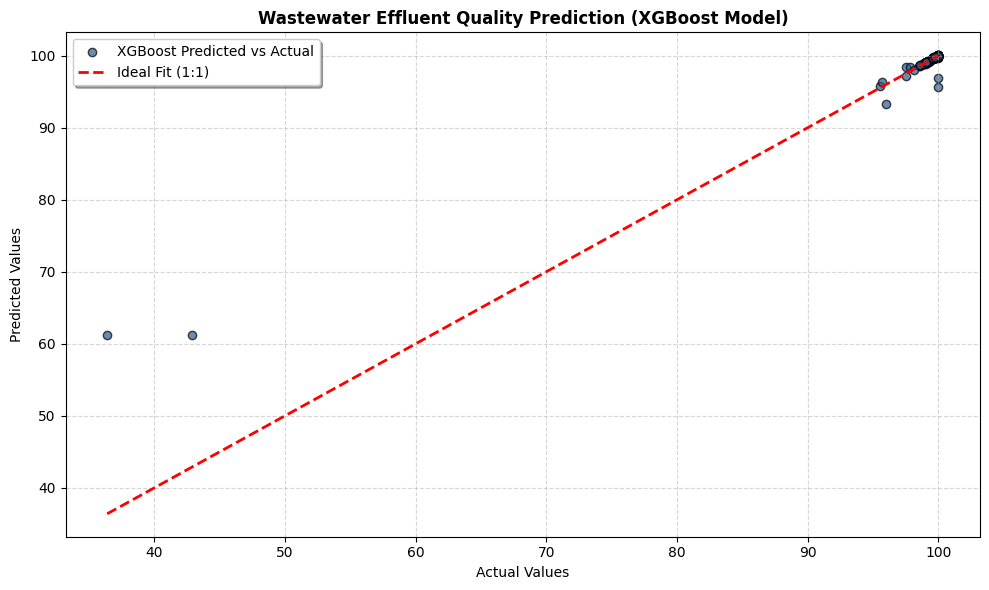

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
# XGBoost Model Prediction
y_pred_xgb = xgb_model.predict(X_test)
# Plot the actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_xgb, color='#2b5c8f', alpha=0.7, edgecolors='k', label='XGBoost Predicted vs Actual')

# Perfect fit line 1:1

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit (1:1)')

plt.title('Wastewater Effluent Quality Prediction (XGBoost Model)', fontsize=12, fontweight='bold')
plt.xlabel('Actual Values', fontsize=10)
plt.ylabel('Predicted Values', fontsize=10)
plt.legend(frameon=True, facecolor='white', shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Total Anomalies Detected: 2


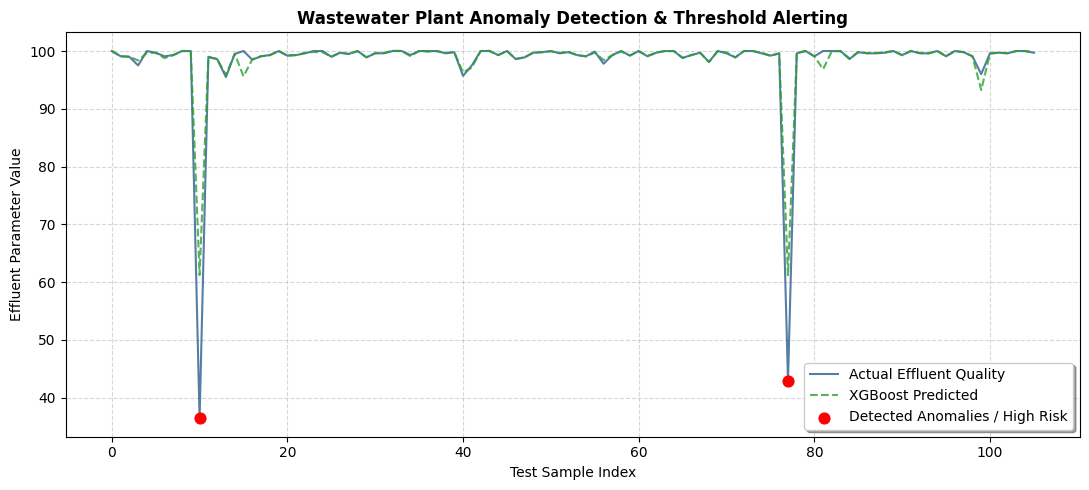

In [20]:
import numpy as np
# Prediction and Absolute Error
y_pred_xgb = xgb_model.predict(X_test)
errors = np.abs(y_test.values - y_pred_xgb)
# Anomaly Threshold
threshold = np.mean(errors) + (2 * np.std(errors))
anomaly_indices = np.where(errors > threshold)[0]
print(f"Total Anomalies Detected: {len(anomaly_indices)}")

# Anomaly Plot created
plt.figure(figsize=(11, 5))
plt.plot(y_test.values, label='Actual Effluent Quality', color='#2b5c8f', alpha=0.8, lw=1.5)
plt.plot(y_pred_xgb, label='XGBoost Predicted', color='#2ca02c', alpha=0.8, linestyle='--', lw=1.5)
# Anomaly point is marked by red color
plt.scatter(anomaly_indices, y_test.values[anomaly_indices], color='red', s=60, label='Detected Anomalies / High Risk', zorder=5)

plt.title('Wastewater Plant Anomaly Detection & Threshold Alerting', fontsize=12, fontweight='bold')
plt.xlabel('Test Sample Index', fontsize=10)
plt.ylabel('Effluent Parameter Value', fontsize=10)
plt.legend(frameon=True, facecolor='white', shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



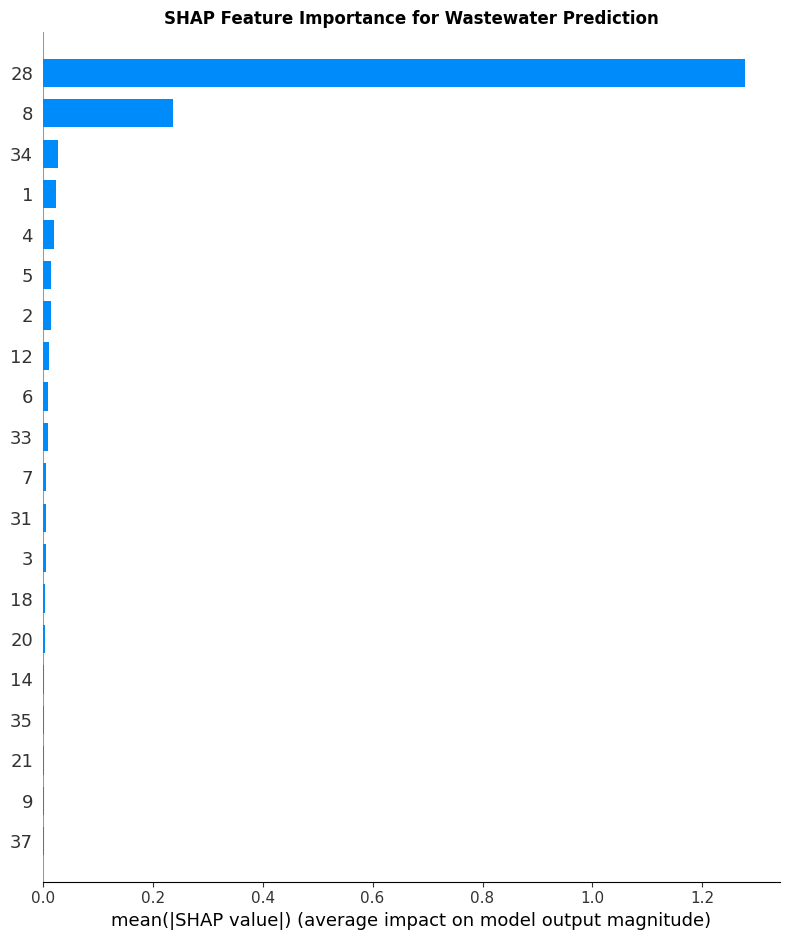

In [21]:
import shap
# SHAP Explainer for XGBoost Model

explainer = shap.Explainer(xgb_model)
shap_values = explainer(X_test)

# Feature Importance Bar Chart

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP Feature Importance for Wastewater Prediction", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [23]:
# Dataset Column INDEX PRINT
for i, col in enumerate(df.columns):
    print(f"Column Index {i}: Sample Value -> {df[col].iloc[0]}")

Column Index 0: Sample Value -> D-1/3/90
Column Index 1: Sample Value -> 44101.0
Column Index 2: Sample Value -> 1.5
Column Index 3: Sample Value -> 7.8
Column Index 4: Sample Value -> nan
Column Index 5: Sample Value -> 407.0
Column Index 6: Sample Value -> 166.0
Column Index 7: Sample Value -> 66.3
Column Index 8: Sample Value -> 4.5
Column Index 9: Sample Value -> 2110
Column Index 10: Sample Value -> 7.9
Column Index 11: Sample Value -> nan
Column Index 12: Sample Value -> 228
Column Index 13: Sample Value -> 70.2
Column Index 14: Sample Value -> 5.5
Column Index 15: Sample Value -> 2120
Column Index 16: Sample Value -> 7.9
Column Index 17: Sample Value -> nan
Column Index 18: Sample Value -> 280.0
Column Index 19: Sample Value -> 94.0
Column Index 20: Sample Value -> 72.3
Column Index 21: Sample Value -> 0.3
Column Index 22: Sample Value -> 2010
Column Index 23: Sample Value -> 7.3
Column Index 24: Sample Value -> nan
Column Index 25: Sample Value -> 84.0
Column Index 26: Sample V